In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/hardik07goel/minilm-data/merges.txt
/kaggle/input/datasets/hardik07goel/minilm-data/train.npy
/kaggle/input/datasets/hardik07goel/minilm-data/valid.npy
/kaggle/input/datasets/hardik07goel/minilm-data/vocab.json


In [2]:
!nvidia-smi
!find /kaggle/input -maxdepth 3 -name "*.npy"

Thu Oct 29 08:19:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!git clone https://github.com/Hardik0710/minilm.git
%cd minilm
!pip install -q regex einops pytest matplotlib
DATA = "/kaggle/input/datasets/hardik07goel/minilm-data"


Cloning into 'minilm'...
remote: Enumerating objects: 95, done.
remote: Counting objects: 100% (95/95), done.
remote: Compressing objects: 100% (75/75), done.
remote: Total 95 (delta 30), reused 80 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (95/95), 93.94 KiB | 15.66 MiB/s, done.
Resolving deltas: 100% (30/30), done.
/kaggle/working/minilm


In [4]:
DATA = "/kaggle/input/datasets/hardik07goel/minilm-data"
import os
print(os.listdir("."))
print(os.listdir(DATA))

['train.py', 'conftest.py', 'tests', 'notes.md', 'compression_sample.py', 'train_bpe.py', 'scratch.py', 'q4_experiment.py', 'requirements.txt', 'resume.png', 'q3_experiment.py', 'encode_dataset.py', 'single.png', 'lr_warmup.py', 'runs', 'minilm', 'README.md', 'plot_runs.py', '.git', '.gitignore']
['merges.txt', 'train.npy', 'valid.npy', 'vocab.json']


In [5]:
!python -m pytest -q

.......................................                                  [100%]
39 passed in 10.12s


In [6]:
import time, torch, numpy as np
from minilm.model.transformer import TransformerLM
from minilm.train.optim import make_optimizer, make_scheduler
from minilm.train.step import train_step
from minilm.train.data import get_batch

train = np.load(f"{DATA}/train.npy", mmap_mode="r")

def bench(compile_it, n=200, warm=20):
    torch.manual_seed(0)
    m = TransformerLM(10000, 256, 512, 4, 16, 1344, 10000.0).cuda()
    opt = make_optimizer(m, 1e-3)
    sch = make_scheduler(opt, 1e-3, 1e-4, 10, 10_000)
    scaler = torch.amp.GradScaler("cuda")
    f = torch.compile(m) if compile_it else m
    for i in range(warm + n):
        if i == warm:
            torch.cuda.synchronize(); t = time.time()
        x, y = get_batch(train, 32, 256, "cuda")
        train_step(f, opt, sch, scaler, x, y, use_amp=True)
    torch.cuda.synchronize()
    return (time.time() - t) / n

a = bench(False); b = bench(True)
print(f"no compile {a*1000:.0f} ms/step, compile {b*1000:.0f} ms/step, speedup {a/b:.2f}x")

W1029 08:36:50.294000 49 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


no compile 2101 ms/step, compile 953 ms/step, speedup 2.21x


In [7]:
import time, torch, numpy as np
from minilm.model.transformer import TransformerLM
from minilm.train.optim import make_optimizer, make_scheduler
from minilm.train.step import train_step
from minilm.train.data import get_batch

# 1. data loading alone
torch.cuda.synchronize(); t = time.time()
for _ in range(20):
    x, y = get_batch(train, 32, 256, "cuda")
torch.cuda.synchronize()
print(f"get_batch: {(time.time()-t)/20*1000:.0f} ms")

# 2. model step alone, on one fixed batch (no disk reads)
m = TransformerLM(10000, 256, 512, 4, 16, 1344, 10000.0).cuda()
opt = make_optimizer(m, 1e-3); sch = make_scheduler(opt, 1e-3, 1e-4, 10, 10_000)
scaler = torch.amp.GradScaler("cuda")
for i in range(25):
    if i == 5:
        torch.cuda.synchronize(); t = time.time()
    train_step(m, opt, sch, scaler, x, y, use_amp=True)
torch.cuda.synchronize()
print(f"train_step (fixed batch): {(time.time()-t)/20*1000:.0f} ms")

get_batch: 606 ms
train_step (fixed batch): 111 ms


In [10]:
!mkdir -p /kaggle/temp
!cp {DATA}/train.npy /kaggle/temp/train.npy
!cp {DATA}/valid.npy /kaggle/temp/valid.npy
!ls -lh /kaggle/temp
!df -h /kaggle/temp /kaggle/working

total 1.1G
-rw-r--r-- 1 root root 1.1G Oct 29 08:45 train.npy
-rw-r--r-- 1 root root  11M Oct 29 08:45 valid.npy
Filesystem      Size  Used Avail Use% Mounted on
overlay         8.0T  7.0T  1.1T  88% /
/dev/loop2       20G  880K   20G   1% /kaggle/working


In [11]:
import time, torch, numpy as np
from minilm.train.data import get_batch
train = np.load("/kaggle/temp/train.npy", mmap_mode="r")
get_batch(train, 32, 256, "cuda")
torch.cuda.synchronize(); t = time.time()
for _ in range(20):
    x, y = get_batch(train, 32, 256, "cuda")
torch.cuda.synchronize()
print(f"get_batch (local): {(time.time()-t)/20*1000:.0f} ms")

get_batch (local): 1 ms


In [12]:
import time, torch, numpy as np
from minilm.model.transformer import TransformerLM
from minilm.train.optim import make_optimizer, make_scheduler
from minilm.train.step import train_step
from minilm.train.data import get_batch

train = np.load("/kaggle/temp/train.npy", mmap_mode="r")

def bench(compile_it, n=200, warm=20):
    torch.manual_seed(0)
    m = TransformerLM(10000, 256, 512, 4, 16, 1344, 10000.0).cuda()
    opt = make_optimizer(m, 1e-3)
    sch = make_scheduler(opt, 1e-3, 1e-4, 10, 10_000)
    scaler = torch.amp.GradScaler("cuda")
    f = torch.compile(m) if compile_it else m
    for i in range(warm + n):
        if i == warm:
            torch.cuda.synchronize(); t = time.time()
        x, y = get_batch(train, 32, 256, "cuda")
        train_step(f, opt, sch, scaler, x, y, use_amp=True)
    torch.cuda.synchronize()
    return (time.time() - t) / n

a1 = bench(False); a2 = bench(False); b = bench(True)
print(f"no compile {a1*1000:.0f} / {a2*1000:.0f} ms/step, compile {b*1000:.0f} ms/step, speedup {min(a1,a2)/b:.2f}x")

no compile 119 / 107 ms/step, compile 86 ms/step, speedup 1.24x


In [13]:
!python train.py --train-data /kaggle/temp/train.npy --val-data /kaggle/temp/valid.npy --out-dir /kaggle/working/runs/pilot_1e-4 --lr 1e-4 --steps 300 --eval-every 50 --ckpt-every 1000 --fp16
!python train.py --train-data /kaggle/temp/train.npy --val-data /kaggle/temp/valid.npy --out-dir /kaggle/working/runs/pilot_3e-4 --lr 3e-4 --steps 300 --eval-every 50 --ckpt-every 1000 --fp16
!python train.py --train-data /kaggle/temp/train.npy --val-data /kaggle/temp/valid.npy --out-dir /kaggle/working/runs/pilot_1e-3 --lr 1e-3 --steps 300 --eval-every 50 --ckpt-every 1000 --fp16
!python train.py --train-data /kaggle/temp/train.npy --val-data /kaggle/temp/valid.npy --out-dir /kaggle/working/runs/pilot_3e-3 --lr 3e-3 --steps 300 --eval-every 50 --ckpt-every 1000 --fp16
!python train.py --train-data /kaggle/temp/train.npy --val-data /kaggle/temp/valid.npy --out-dir /kaggle/working/runs/pilot_1e-2 --lr 1e-2 --steps 300 --eval-every 50 --ckpt-every 1000 --fp16

parameters: 22,696,448  device: cuda  amp: True
step 1 loss 9.3921 lr 0.00e+00 gnorm 0.966
step 10 loss 9.1225 lr 6.00e-05 gnorm 0.997
step 20 loss 8.1181 lr 1.00e-04 gnorm 1.506
step 30 loss 7.1377 lr 9.95e-05 gnorm 1.728
step 40 loss 6.4830 lr 9.84e-05 gnorm 1.585
step 50 loss 5.8841 lr 9.69e-05 gnorm 1.181 val 5.8908
step 60 loss 5.5221 lr 9.48e-05 gnorm 0.860
step 70 loss 5.0406 lr 9.22e-05 gnorm 0.681
step 80 loss 5.0214 lr 8.92e-05 gnorm 0.529
step 90 loss 4.8806 lr 8.57e-05 gnorm 0.444
step 100 loss 4.7488 lr 8.19e-05 gnorm 0.444 val 4.7080
step 110 loss 4.6276 lr 7.78e-05 gnorm 0.452
step 120 loss 4.3902 lr 7.34e-05 gnorm 0.469
step 130 loss 4.3935 lr 6.87e-05 gnorm 0.456
step 140 loss 4.2834 lr 6.39e-05 gnorm 0.533
step 150 loss 4.3063 lr 5.90e-05 gnorm 0.419 val 4.3004
step 160 loss 4.2245 lr 5.40e-05 gnorm 0.430
step 170 loss 4.2274 lr 4.90e-05 gnorm 0.423
step 180 loss 4.0927 lr 4.42e-05 gnorm 0.433
step 190 loss 4.0171 lr 3.94e-05 gnorm 0.449
step 200 loss 4.1726 lr 3.48e-

In [14]:
!python train.py --train-data /kaggle/temp/train.npy --val-data /kaggle/temp/valid.npy --out-dir /kaggle/working/runs/pilot_3e-2 --lr 3e-2 --steps 300 --eval-every 50 --ckpt-every 1000 --fp16
!python train.py --train-data /kaggle/temp/train.npy --val-data /kaggle/temp/valid.npy --out-dir /kaggle/working/runs/pilot_1e-1 --lr 1e-1 --steps 300 --eval-every 50 --ckpt-every 1000 --fp16

parameters: 22,696,448  device: cuda  amp: True
step 1 loss 9.3921 lr 0.00e+00 gnorm 0.966
step 10 loss 7.6635 lr 1.80e-02 gnorm 2.895
step 20 loss 8.8570 lr 3.00e-02 gnorm 3.200
non-finite loss, stopping
parameters: 22,696,448  device: cuda  amp: True
step 1 loss 9.3921 lr 0.00e+00 gnorm 0.966
step 10 loss 17.3521 lr 6.00e-02 gnorm 18.257
non-finite loss, stopping


In [15]:
!python plot_runs.py /kaggle/working/pilots.png /kaggle/working/runs/pilot_1e-4/log.csv /kaggle/working/runs/pilot_3e-4/log.csv /kaggle/working/runs/pilot_1e-3/log.csv /kaggle/working/runs/pilot_3e-3/log.csv /kaggle/working/runs/pilot_1e-2/log.csv /kaggle/working/runs/pilot_3e-2/log.csv /kaggle/working/runs/pilot_1e-1/log.csv

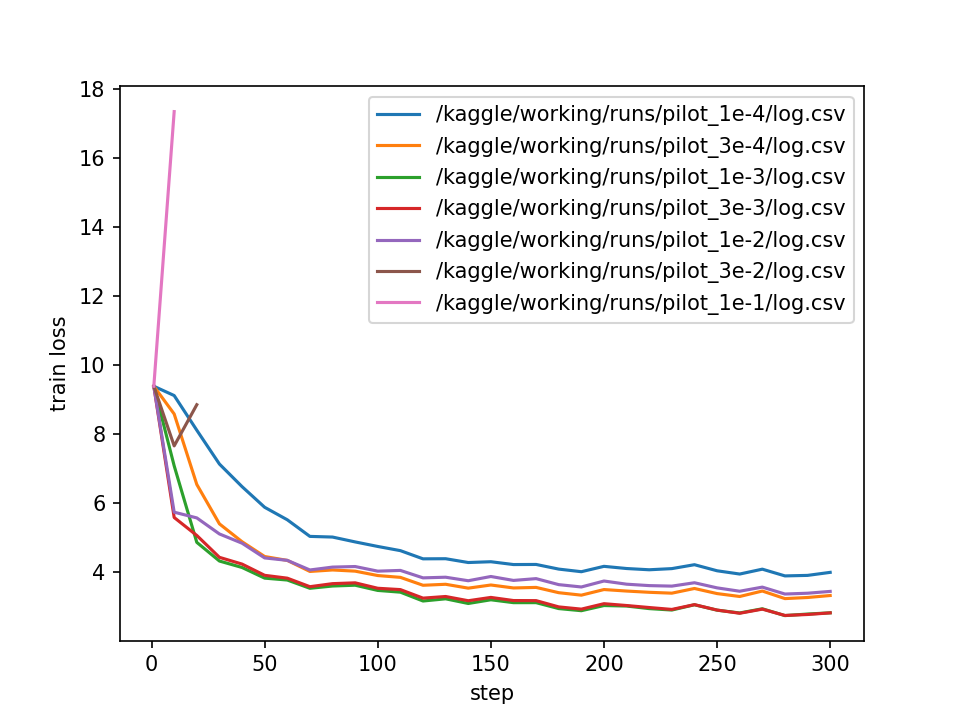

In [16]:
from IPython.display import Image
Image("/kaggle/working/pilots.png")

In [17]:
import shutil
shutil.make_archive("/kaggle/working/runs", "zip", "/kaggle/working", "runs")

'/kaggle/working/runs.zip'

In [18]:
!ls -lh /kaggle/temp

total 1.1G
-rw-r--r-- 1 root root 1.1G Oct 29 08:45 train.npy
-rw-r--r-- 1 root root  11M Oct 29 08:45 valid.npy


In [19]:
!python train.py --train-data /kaggle/temp/train.npy --val-data /kaggle/temp/valid.npy --out-dir /kaggle/working/runs/main --lr 3e-3 --steps 5000 --eval-every 250 --log-every 10 --ckpt-every 500 --fp16 --compile

parameters: 22,696,448  device: cuda  amp: True
step 1 loss 9.3921 lr 0.00e+00 gnorm 0.966
step 10 loss 8.9105 lr 1.08e-04 gnorm 1.052
step 20 loss 7.1915 lr 2.28e-04 gnorm 1.762
step 30 loss 5.8253 lr 3.48e-04 gnorm 1.166
step 40 loss 4.9570 lr 4.68e-04 gnorm 0.718
step 50 loss 4.3786 lr 5.88e-04 gnorm 0.457
step 60 loss 4.1717 lr 7.08e-04 gnorm 0.416
step 70 loss 3.8165 lr 8.28e-04 gnorm 0.408
step 80 loss 3.8249 lr 9.48e-04 gnorm 0.431
step 90 loss 3.7760 lr 1.07e-03 gnorm 0.444
step 100 loss 3.6145 lr 1.19e-03 gnorm 0.526
step 110 loss 3.5268 lr 1.31e-03 gnorm 0.609
step 120 loss 3.2451 lr 1.43e-03 gnorm 0.494
step 130 loss 3.2801 lr 1.55e-03 gnorm 0.509
step 140 loss 3.1077 lr 1.67e-03 gnorm 0.480
step 150 loss 3.1985 lr 1.79e-03 gnorm 0.465
step 160 loss 3.1197 lr 1.91e-03 gnorm 0.442
step 170 loss 3.0953 lr 2.03e-03 gnorm 0.547
step 180 loss 2.9215 lr 2.15e-03 gnorm 0.447
step 190 loss 2.8525 lr 2.27e-03 gnorm 0.428
step 200 loss 3.0364 lr 2.39e-03 gnorm 0.454
step 210 loss 2.99

In [20]:
!cd /kaggle/working && zip -r runs_all.zip runs pilots.png
!ls -lh /kaggle/working/runs_all.zip


  adding: runs/ (stored 0%)
  adding: runs/pilot_1e-2/ (stored 0%)
  adding: runs/pilot_1e-2/args.json (deflated 51%)
  adding: runs/pilot_1e-2/log.csv (deflated 49%)
  adding: runs/pilot_1e-2/ckpt.pt (deflated 9%)
  adding: runs/pilot_1e-1/ (stored 0%)
  adding: runs/pilot_1e-1/args.json (deflated 51%)
  adding: runs/pilot_1e-1/log.csv (deflated 22%)
  adding: runs/pilot_1e-3/ (stored 0%)
  adding: runs/pilot_1e-3/args.json (deflated 51%)
  adding: runs/pilot_1e-3/log.csv (deflated 50%)
  adding: runs/pilot_1e-3/ckpt.pt (deflated 10%)
  adding: runs/pilot_3e-3/ (stored 0%)
  adding: runs/pilot_3e-3/args.json (deflated 51%)
  adding: runs/pilot_3e-3/log.csv (deflated 50%)
  adding: runs/pilot_3e-3/ckpt.pt (deflated 9%)
  adding: runs/pilot_3e-2/ (stored 0%)
  adding: runs/pilot_3e-2/args.json (deflated 51%)
  adding: runs/pilot_3e-2/log.csv (deflated 31%)
  adding: runs/pilot_3e-4/ (stored 0%)
  adding: runs/pilot_3e-4/args.json (deflated 51%)
  adding: runs/pilot_3e-4/log.csv (deflate

In [21]:
from IPython.display import FileLink
FileLink("/kaggle/working/runs_all.zip")

/kaggle/working/runs_all.zip

In [22]:
!cd /kaggle/working && zip -r main_only.zip runs/main
!ls -lh /kaggle/working/main_only.zip

  adding: runs/main/ (stored 0%)
  adding: runs/main/args.json (deflated 51%)
  adding: runs/main/log.csv (deflated 54%)
  adding: runs/main/ckpt.pt (deflated 8%)
-rw-r--r-- 1 root root 239M Oct 29 09:24 /kaggle/working/main_only.zip


In [23]:
from IPython.display import FileLink
FileLink("/kaggle/working/main_only.zip")

/kaggle/working/main_only.zip